# Walkthrough

The same steps as `python -m spl_predictor`, one at a time, with the intermediate tables on show.

**Question.** Before a Saudi Pro League match, can we say whether it ends in a home win, a draw or an away win, better than always guessing "home win"?

In [1]:
import pandas as pd

from spl_predictor import plots
from spl_predictor.data import load_matches
from spl_predictor.evaluate import summarise, walk_forward, weekly_accuracy
from spl_predictor.features import add_features
from spl_predictor.forecast import most_likely_winners, predict_week
from spl_predictor.models import candidates
from spl_predictor.pipeline import BACKTEST_SEASONS, HOLDOUT_SEASON, next_week

pd.set_option("display.float_format", "{:.2f}".format)

## 1. Data

Every league match from FBref, 2014-15 to the current season. Unplayed fixtures have no score yet.

In [2]:
matches = load_matches()
played = matches.dropna(subset=["result"])
print(f"{len(played):,} played matches, {matches['season'].nunique()} seasons")
played["result"].value_counts(normalize=True)

2,940 played matches, 13 seasons


result
H   0.44
A   0.33
D   0.23
Name: proportion, dtype: float64

Home wins are the most common result (about 44%), draws the least (about 23%). Always guessing "home win" is the baseline to beat.

## 2. Features: two numbers per match

- `last_diff`: home team's goal difference per game last season, minus the away team's.
- `form_diff`: the same over each team's last 10 league matches.

Both use only results from before the match.

In [3]:
data = add_features(matches)
data[["season", "date", "home", "away", "last_diff", "form_diff", "result"]].tail(12).head(6)

,season,date,home,away,last_diff,form_diff,result
2958,2026-27,2027-05-24,Al-Qadsiah,Al-Hazem,2.00,2.00,NaN
2959,2026-27,2027-05-24,Diriyah Club,Al-Khaleej,-0.84,-0.84,NaN
2960,2026-27,2027-05-24,Neom,Al-Shabab,0.24,0.24,NaN
2961,2026-27,2027-05-28,Al-Ahli,Neom,1.50,1.50,NaN
2962,2026-27,2027-05-28,Al-Fateh,Abha,0.67,0.67,NaN
2963,2026-27,2027-05-28,Al-Fayha,Al-Ettifaq,-0.26,-0.26,NaN


## 3. Backtest: train on earlier seasons, test on the next, nine times

In [4]:
backtest, train_scores = walk_forward(data, candidates(), BACKTEST_SEASONS)
summary = summarise(backtest, train_scores)
summary[["matches", "accuracy", "log_loss", "train_log_loss", "gap"]]

,matches,accuracy,log_loss,train_log_loss,gap
model,,,,,
Always home win,2176.00,0.44,1.07,1.07,-0.01
Logistic regression,2176.00,0.52,0.99,0.99,0.01
Random forest,2176.00,0.44,1.54,0.29,1.25
Gradient boosting,2176.00,0.47,1.09,0.72,0.37


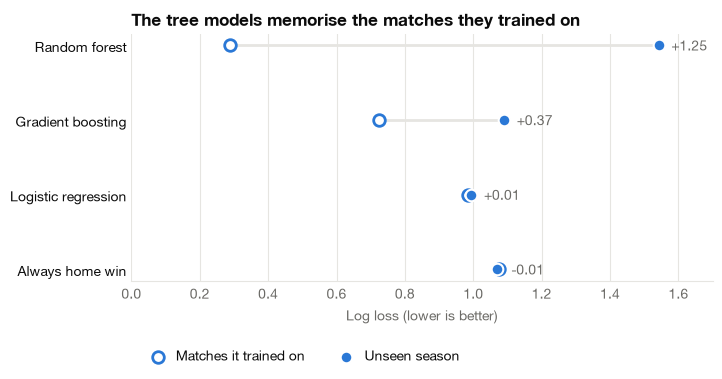

In [5]:
plots.overfitting_gap(summary);

The random forest is far better on matches it trained on than on new ones: it memorised. Logistic regression has no gap.

## 4. The 2025-26 season, untouched until now

In [6]:
holdout, holdout_train = walk_forward(data, candidates(), [HOLDOUT_SEASON])
holdout_summary = summarise(holdout, holdout_train)
holdout_summary[["accuracy", "log_loss"]]

,accuracy,log_loss
model,,
Always home win,0.44,1.06
Logistic regression,0.57,0.90
Random forest,0.50,2.01
Gradient boosting,0.57,0.94


In [7]:
lr = holdout[holdout["model"] == "Logistic regression"]
pd.crosstab(lr["result"], lr["pick"], rownames=["actual"], colnames=["picked"])

picked,A,H
actual,,
A,68,33
D,26,44
H,28,107


It never picks a draw: a draw is never the single most likely result for any match. Draws are a quarter of all matches, so that costs it about a quarter of its chances.

In [8]:
weeks = weekly_accuracy(holdout)
weeks[weeks["model"] == "Logistic regression"]["right"].describe()[["mean", "min", "max"]]

mean   5.15
min    3.00
max    8.00
Name: right, dtype: float64

## 5. The next matchweek

In [9]:
season, week = next_week(data)
picks = predict_week(candidates()["Logistic regression"], data, season, week)
print(season, "matchweek", week)
picks[["date", "home", "away", "p_H", "p_D", "p_A", "pick"]]

2026-27 matchweek 12


,date,home,away,p_H,p_D,p_A,pick
0,2026-10-29,Al-Khaleej,Al-Hazem,0.45,0.26,0.29,home win
1,2026-10-29,Al-Nassr,Al-Kholood,0.80,0.15,0.04,home win
2,2026-10-29,Al-Riyadh,Al-Qadsiah,0.10,0.17,0.73,away win
3,2026-10-30,Abha,Al-Ittihad,0.15,0.20,0.65,away win
4,2026-10-30,Al-Shabab,Al-Ahli,0.16,0.21,0.63,away win
5,2026-10-30,Diriyah Club,Neom,0.28,0.25,0.48,away win
6,2026-10-31,Al-Fayha,Al-Faisaly,0.55,0.25,0.20,home win
7,2026-10-31,Al-Hilal,Al-Fateh,0.82,0.14,0.04,home win
8,2026-10-31,Al-Taawoun,Al-Ettifaq,0.37,0.25,0.38,away win


In [10]:
most_likely_winners(picks).head(5)

,club,opponent,win_chance,venue
0,Al-Hilal,Al-Fateh,0.82,home
1,Al-Nassr,Al-Kholood,0.80,home
2,Al-Qadsiah,Al-Riyadh,0.73,away
3,Al-Ittihad,Abha,0.65,away
4,Al-Ahli,Al-Shabab,0.63,away
